# A principled LDA pipeline for kinematic group classification

Classifying **DGS / Gesture / Learners_1 / Learners_2** from arm and wrist kinematics.

This notebook is built for data with three properties that the standard LDA tutorials
(iris-based) do not have:

| | iris tutorials | this data |
|---|---|---|
| observations | independent flowers | windows **nested in participants** |
| features | 4, weakly correlated | ~20, heavily collinear |
| consequence | plain k-fold is valid; raw weights readable | needs **grouped** CV; weights **not** readable |

Run the cells in order. Each stage prints what it found and why it matters.

**Stages**
1. Load and hygiene — fix the unit of observation
2. Collinearity diagnostics
3. LDA assumption checks
4. Three ways to handle collinearity
5. Grouped cross-validation
6. Is the classification real? (permutation test)
7. Which discriminants are interpretable? (permutation on eigenvalues)
8. Are the loadings stable? (participant bootstrap)
9. Final figures and reporting checklist

In [1]:
%matplotlib inline
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg, stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis as LDA,
    QuadraticDiscriminantAnalysis as QDA,
)
from sklearn.feature_selection import f_classif
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore", category=UserWarning)
print("ready")

ready


## Configuration

`GROUP_COL` is the important one. If your rows are windows drawn from a smaller set of
participants, **that column must exist** — without it there is no valid way to
cross-validate or test anything below. If your CSV does not have it, stop here and
regenerate the CSV with the participant ID retained.

`DURATION_COL` is used to check whether your `_n` (count) features are confounded with
trial length. Set it if you have it.

`QUICK = True` drops the permutation/bootstrap counts so you can run the whole notebook
in under a minute while developing. Set it to `False` for anything you report.

In [10]:
CSV          = os.path.join("Datasets", "sampled_merged_250_cleanforPCA.csv")
LABEL_COL    = "groupID"
GROUP_COL    = None   # None only if there is genuinely one row per participant FLAG: we need to add it here
DURATION_COL = None               # e.g. "duration_s"
OUTDIR       = "lda_out"
N_SPLITS     = 5
CORR_CUT     = 0.30               # dendrogram cut on 1-|rho|  =>  merges features with |rho| > 0.70
RANDOM_STATE = 1

QUICK   = True
N_PERM  = 100 if QUICK else 1000
N_BOOT  = 100 if QUICK else 500

os.makedirs(OUTDIR, exist_ok=True)
rng = np.random.default_rng(RANDOM_STATE)

## Stage 1 — Load and hygiene

Three things happen here.

**Unit of observation.** If rows are nested in participants, a model can succeed by
memorising *individuals* rather than *groups*. Every CV below therefore splits on
participant. This is the single most consequential difference from the tutorial code.

**Drop what breaks the fit.** Non-finite rows and zero-variance features destabilise the
inversion of the within-class covariance matrix.

**Baseline.** Note the majority-class rate — accuracy means nothing without it.

In [11]:
data = pd.read_csv(CSV)
print("raw shape:", data.shape)

y = data[LABEL_COL].astype(str)
drop = [LABEL_COL] + ([GROUP_COL] if GROUP_COL else [])
X = data.drop(columns=drop).select_dtypes(include=[np.number]).copy()

if GROUP_COL and GROUP_COL in data.columns:
    groups = data[GROUP_COL].astype(str)
    n_part = groups.nunique()
    print(f"participants: {n_part}   rows per participant: {len(data)/n_part:.1f}")
    print(data.groupby(LABEL_COL)[GROUP_COL].nunique().rename("n participants"))
    if len(data) / n_part > 1.5:
        print("\n>> Rows are NESTED. All CV below is grouped on participant.")
else:
    groups = pd.Series(np.arange(len(data)).astype(str))
    print("\n!! No participant column: everything below ASSUMES independent rows.")

bad = ~np.isfinite(X.to_numpy()).all(axis=1)
if bad.any():
    print(f"dropping {bad.sum()} rows with NaN/inf")
    X, y, groups = X[~bad], y[~bad], groups[~bad]

nzv = X.columns[X.std(ddof=1) < 1e-10]
if len(nzv):
    print("dropping zero-variance features:", list(nzv))
    X = X.drop(columns=nzv)

feat_names = list(X.columns)
classes = np.array(sorted(y.unique()))
p, g, N = X.shape[1], len(classes), len(X)
n_lds = min(p, g - 1)

print(f"\nN={N}  p={p}  g={g}  ->  at most {n_lds} discriminant functions")
print(y.value_counts())
print(f"majority-class baseline = {y.value_counts(normalize=True).max():.3f}")

raw shape: (928, 60)

!! No participant column: everything below ASSUMES independent rows.

N=928  p=59  g=4  ->  at most 3 discriminant functions
groupID
Learners_1    244
Gesture       238
Learners_2    233
DGS           213
Name: count, dtype: int64
majority-class baseline = 0.263


### Count / duration confound

If `_n` features are **raw counts** over a trial rather than **rates**, they partly index
how long the trial was, not how the movement was structured. Since count features dominate
LD1 in this dataset, a strong correlation here would be a confound, not a finding.

In [12]:
if DURATION_COL and DURATION_COL in data.columns:
    dur = data.loc[X.index, DURATION_COL]
    for c in [c for c in feat_names if c.endswith("_n")]:
        r = stats.spearmanr(X[c], dur).statistic
        print(f"{c:42s} rho={r:+.2f}" + ("   <-- RED FLAG: normalise by duration" if abs(r) > .5 else ""))
else:
    print("DURATION_COL not set - check manually whether '_n' features are counts or rates.")

DURATION_COL not set - check manually whether '_n' features are counts or rates.


## Stage 2 — Collinearity diagnostics

Kinematic features are near-duplicates of one another. Two consequences:

- **Raw LDA weights become unreadable.** Two correlated features can take large opposing
  weights that cancel, so a genuinely important feature shows a near-zero weight.
- **The within-class covariance inversion becomes unstable**, so weights swing between
  refits.

Condition number gives severity; VIF gives per-feature severity; the **dendrogram gives
structure** — which features are effectively the same measurement. That last one is the
most useful, because it tells you the feature *families* you will end up interpreting.

In [13]:
Xs = StandardScaler().fit_transform(X)
corr = pd.DataFrame(Xs, columns=feat_names).corr(method="spearman")

eigv = np.linalg.eigvalsh(corr.to_numpy())
cond = np.sqrt(eigv.max() / max(eigv.min(), 1e-12))
print(f"condition number: {cond:,.0f}    (<30 fine | 30-100 moderate | >100 severe)")

vif = pd.Series(np.diag(np.linalg.pinv(corr.to_numpy())), index=feat_names)
print(f"\nVIF > 10 for {int((vif > 10).sum())}/{p} features. Worst:")
print(vif.sort_values(ascending=False).head(8).round(1).to_string())

condition number: 114    (<30 fine | 30-100 moderate | >100 severe)

VIF > 10 for 23/59 features. Worst:
band1_0.5-2.0Hz_band_power_total_arm    662.6
band2_2.0-5.0Hz_band_power_total_arm    606.0
band2_2.0-5.0Hz_centroid_total_arm      168.0
band2_2.0-5.0Hz_entropy_total_arm       151.5
band3_5.0-8.0Hz_centroid_total_arm      141.7
band3_5.0-8.0Hz_entropy_total_arm       141.6
RIGHT_mcp_tip_distance_mean              56.7
RIGHT_mcp_tip_distance_std               36.8


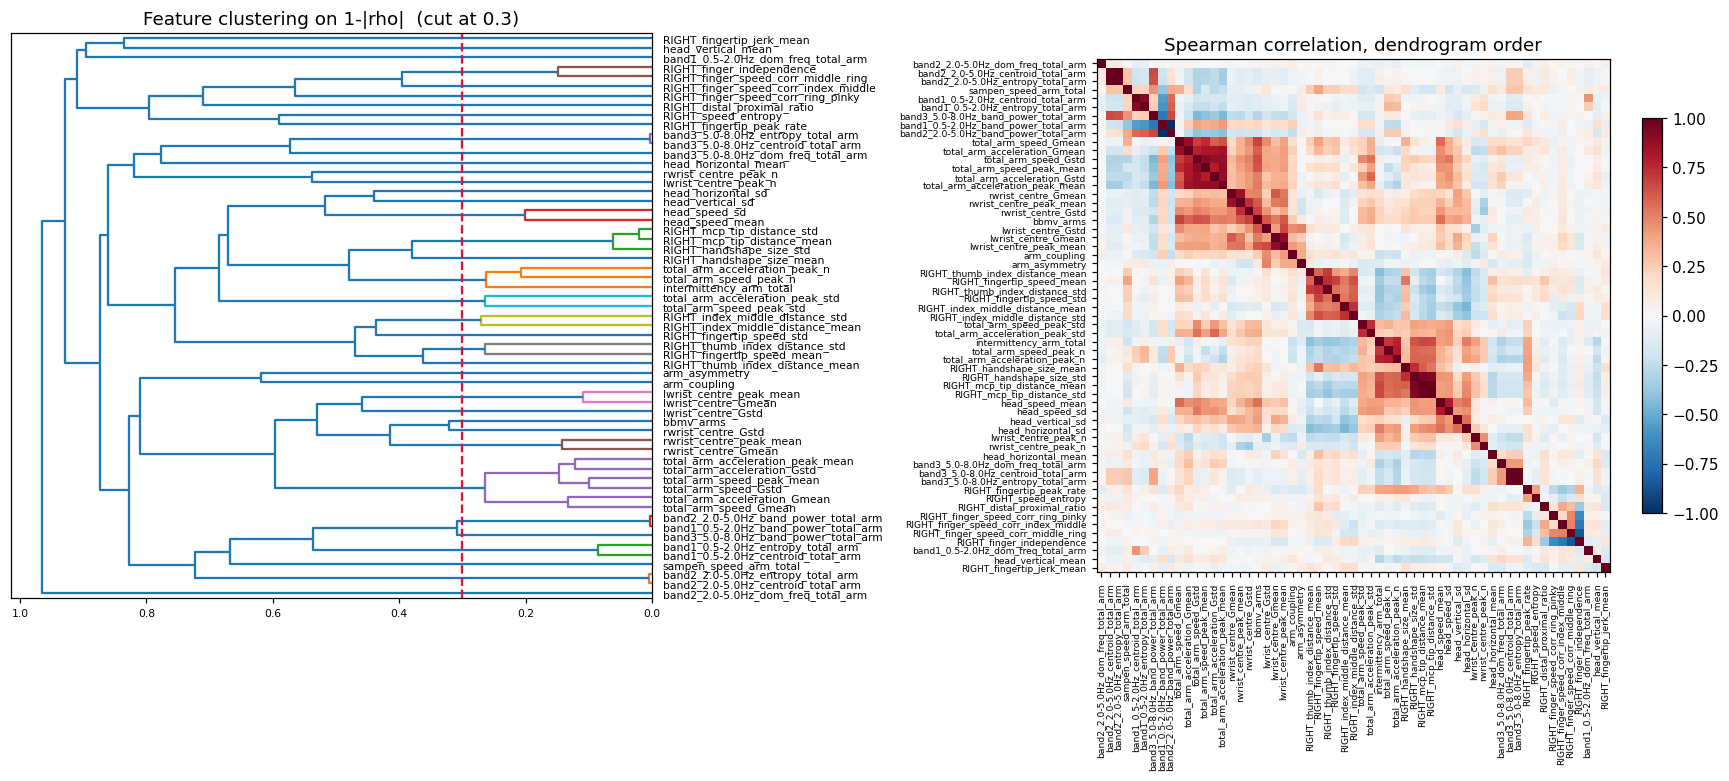

59 features collapse to 39 clusters at |rho| > 0.70


In [14]:
dist = 1.0 - corr.abs().to_numpy()
np.fill_diagonal(dist, 0.0)
dist = (dist + dist.T) / 2
Zlink = hierarchy.linkage(squareform(dist, checks=False), method="average")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
dn = hierarchy.dendrogram(Zlink, labels=feat_names, ax=axes[0],
                          orientation="left", color_threshold=CORR_CUT)
axes[0].axvline(CORR_CUT, color="crimson", ls="--")
axes[0].set_title(f"Feature clustering on 1-|rho|  (cut at {CORR_CUT})")
axes[0].tick_params(labelsize=7)

order = dn["leaves"]
im = axes[1].imshow(corr.to_numpy()[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(p)); axes[1].set_yticks(range(p))
axes[1].set_xticklabels([feat_names[i] for i in order], rotation=90, fontsize=6)
axes[1].set_yticklabels([feat_names[i] for i in order], fontsize=6)
axes[1].set_title("Spearman correlation, dendrogram order")
fig.colorbar(im, ax=axes[1], shrink=.7)
fig.tight_layout(); fig.savefig(f"{OUTDIR}/01_collinearity.png", dpi=150); plt.show()

cl = hierarchy.fcluster(Zlink, CORR_CUT, criterion="distance")
print(f"{p} features collapse to {cl.max()} clusters at |rho| > {1-CORR_CUT:.2f}")

## Stage 3 — Assumption checks

LDA assumes (a) within-class multivariate normality and (b) equal covariance matrices
across classes.

**Normality violations are mostly benign for classification.** They matter mainly for the
parametric tests in stage 7. Descriptive skew/kurtosis per class is enough; log- or
sqrt-transform badly skewed features if there are several.

**Box's M is nearly useless as a decision rule.** It is hypersensitive to sample size —
with N in the hundreds it rejects almost regardless of how similar the covariances
actually are. Treating `p < .001` as "must switch to QDA" is a classic overreaction. The
honest test is empirical: fit QDA alongside LDA under identical grouped CV (stage 5) and
see whether relaxing the assumption actually buys accuracy.

In [15]:
sk = pd.DataFrame({c: stats.skew(Xs[(y == c).to_numpy()], axis=0) for c in classes}, index=feat_names)
ku = pd.DataFrame({c: stats.kurtosis(Xs[(y == c).to_numpy()], axis=0) for c in classes}, index=feat_names)

print("worst within-class |skew| (>2 is a concern):")
print(sk.abs().max(axis=1).sort_values(ascending=False).head(5).round(2).to_string())
print(f"\n|skew| > 2 in some class:            {int((sk.abs() > 2).any(axis=1).sum())}/{p}")
print(f"|excess kurtosis| > 7 in some class: {int((ku.abs() > 7).any(axis=1).sum())}/{p}")

worst within-class |skew| (>2 is a concern):
band3_5.0-8.0Hz_dom_freq_total_arm      15.33
band2_2.0-5.0Hz_dom_freq_total_arm      13.06
head_vertical_sd                         6.88
head_vertical_mean                       6.60
band3_5.0-8.0Hz_band_power_total_arm     6.14

|skew| > 2 in some class:            23/59
|excess kurtosis| > 7 in some class: 22/59


C:\Users\kadava\AppData\Local\Temp\ipykernel_27624\742563060.py:1: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  sk = pd.DataFrame({c: stats.skew(Xs[(y == c).to_numpy()], axis=0) for c in classes}, index=feat_names)
C:\Users\kadava\AppData\Local\Temp\ipykernel_27624\742563060.py:2: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  ku = pd.DataFrame({c: stats.kurtosis(Xs[(y == c).to_numpy()], axis=0) for c in classes}, index=feat_names)


In [16]:
def box_m(Xarr, yarr):
    cls = np.unique(yarr)
    Nn, pp, gg = Xarr.shape[0], Xarr.shape[1], len(cls)
    pooled = np.zeros((pp, pp)); logdets, ns = [], []
    for c in cls:
        Xc = Xarr[yarr == c]; nc = len(Xc); ns.append(nc)
        Sc = np.cov(Xc, rowvar=False)
        pooled += (nc - 1) * Sc
        logdets.append(np.linalg.slogdet(Sc)[1])
    pooled /= (Nn - gg)
    M = (Nn - gg) * np.linalg.slogdet(pooled)[1] - sum((n - 1) * ld for n, ld in zip(ns, logdets))
    c1 = (sum(1/(n-1) for n in ns) - 1/(Nn-gg)) * (2*pp**2 + 3*pp - 1) / (6*(pp+1)*(gg-1))
    chi2 = M * (1 - c1); df = pp*(pp+1)*(gg-1)/2
    return M, chi2, df, stats.chi2.sf(chi2, df)

if min(y.value_counts()) > p + 2:
    M, chi2, df, pv = box_m(Xs, y.to_numpy())
    print(f"Box's M = {M:.1f}   chi2 = {chi2:.1f}   df = {df:.0f}   p = {pv:.3g}")
    print("Interpret with the caveat above - compare LDA vs QDA in stage 5 instead.")
else:
    print("skipped: a class has fewer rows than features + 2")

Box's M = 41444.4   chi2 = 36985.1   df = 5310   p = 0
Interpret with the caveat above - compare LDA vs QDA in stage 5 instead.


## Stage 4 — Three ways to handle collinearity

These optimise different things, so "which is best" depends on what you want to claim.

**A. Correlation-cluster selection** — cut the dendrogram, keep one *medoid* per cluster.
Features stay in original units, so loadings mean something physical. Deterministic given a
threshold, which is what makes it **reproducible**. Contrast with stepwise or iterative
VIF-dropping: those are order-dependent, so two analysts get different feature sets from
the same data. Avoid them.

**B. PCA then LDA.**
*Buys:* guarantees the within-class covariance is invertible (matters when p approaches N —
**not your situation**); PCs are orthogonal so weight instability disappears entirely;
dropping trailing components denoises.
*Costs:* PCA is **unsupervised** — it maximises *total* variance, not *between-group*
variance. A component explaining 2% of variance can carry the entire group effect, and a
95% cutoff would discard it. This is the real red flag, and it is checkable (last cell of
this notebook). Second cost: LD1 becomes a combination of PCs which are combinations of
features, so the interpretation moves a level away.

**C. Shrinkage LDA** (Ledoit–Wolf) — keeps every feature, regularises the covariance
estimate instead. Usually the most stable, but individual weights still are not readable,
so you interpret structure coefficients either way.

**D. QDA** is included only as a reference, to test the equal-covariance assumption
empirically rather than via Box's M.

> With p ≈ 20 and N ≈ 1000, PCA solves a problem you do not have at a cost you would
> rather not pay. But run the comparison — if it wins by a real margin, that is data.

The selector is written as a scikit-learn transformer so it lives **inside** the CV
pipeline. It never sees `y`, so it cannot leak class information.

In [17]:
class CorrClusterSelect(BaseEstimator, TransformerMixin):
    '''Cluster features on 1-|Spearman rho|; keep one medoid per cluster. Unsupervised.'''
    def __init__(self, threshold=0.30):
        self.threshold = threshold

    def fit(self, X, y=None):
        Xa = np.asarray(X)
        c = np.nan_to_num(pd.DataFrame(Xa).corr(method="spearman").to_numpy(), nan=0.0)
        d = 1.0 - np.abs(c); np.fill_diagonal(d, 0.0); d = (d + d.T) / 2
        lab = hierarchy.fcluster(
            hierarchy.linkage(squareform(d, checks=False), method="average"),
            self.threshold, criterion="distance")
        keep = []
        for k in np.unique(lab):
            idx = np.where(lab == k)[0]
            keep.append(idx[np.argmax(np.abs(c[np.ix_(idx, idx)]).mean(axis=1))])
        self.support_ = np.sort(np.array(keep))
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]


STRATEGIES = {
    "cluster+LDA":   Pipeline([("sc", StandardScaler()),
                               ("sel", CorrClusterSelect(CORR_CUT)),
                               ("lda", LDA(solver="svd", n_components=n_lds))]),
    "PCA+LDA":       Pipeline([("sc", StandardScaler()),
                               ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                               ("lda", LDA(solver="svd", n_components=n_lds))]),
    "shrinkage LDA": Pipeline([("sc", StandardScaler()),
                               ("lda", LDA(solver="eigen", shrinkage="auto", n_components=n_lds))]),
    "QDA (ref)":     Pipeline([("sc", StandardScaler()),
                               ("sel", CorrClusterSelect(CORR_CUT)),
                               ("qda", QDA(reg_param=0.1))]),
}
print("\n".join(STRATEGIES))

cluster+LDA
PCA+LDA
shrinkage LDA
QDA (ref)


## Stage 5 — Grouped cross-validation

`StratifiedGroupKFold(groups=participantID)` keeps every participant entirely on one side
of each split. **Balanced accuracy**, not raw accuracy, because it is not inflated by class
imbalance and its chance level is always 1/g.

Compare against the ungrouped number if you like — the gap is the size of your
pseudoreplication problem.

cluster+LDA      0.793 +/- 0.007   [0.793 0.806 0.791 0.784 0.791]
PCA+LDA          0.797 +/- 0.013   [0.809 0.806 0.807 0.774 0.789]
shrinkage LDA    0.796 +/- 0.033   [0.799 0.857 0.786 0.768 0.769]
QDA (ref)        0.809 +/- 0.020   [0.809 0.846 0.785 0.797 0.806]

chance (balanced) = 0.250


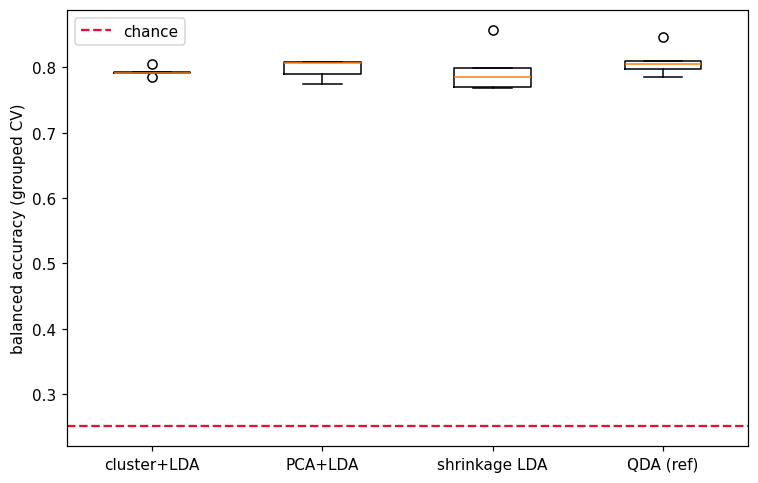

>> QDA wins: covariances differ enough that the LDA equal-covariance assumption is costing you. Report LDA for interpretation but flag this.
selected for interpretation: QDA (ref)


In [18]:
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X, y, groups))

results = {}
for name, pipe in STRATEGIES.items():
    fold = []
    for tr, te in splits:
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        fold.append(balanced_accuracy_score(y.iloc[te], m.predict(X.iloc[te])))
    results[name] = np.array(fold)
    print(f"{name:16s} {np.mean(fold):.3f} +/- {np.std(fold):.3f}   {np.round(fold,3)}")

print(f"\nchance (balanced) = {1/g:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(results.values(), tick_labels=results.keys())
ax.axhline(1/g, color="crimson", ls="--", label="chance")
ax.set_ylabel("balanced accuracy (grouped CV)"); ax.legend()
fig.tight_layout(); fig.savefig(f"{OUTDIR}/02_strategy_comparison.png", dpi=150); plt.show()

BEST = max(results, key=lambda k: results[k].mean())
if "QDA" in BEST:
    print(">> QDA wins: covariances differ enough that the LDA equal-covariance "
          "assumption is costing you. Report LDA for interpretation but flag this.")
print("selected for interpretation:", BEST)
best_pipe = clone(STRATEGIES[BEST])

In [21]:
best_pipe = clone(STRATEGIES["cluster+LDA"])

## Stage 6 — Is the classification real?

Permutation test on balanced accuracy. Group is a **between-participant** factor, so the
null must shuffle labels **at the participant level**. Shuffling row labels would break the
nesting and give a null that is far too easy to beat — a meaningless p-value.

This makes no normality or equal-covariance assumption and respects your nesting. **This is
the number to report.**

observed 0.809   null mean 0.249   p = 0.0099  (100 perms)


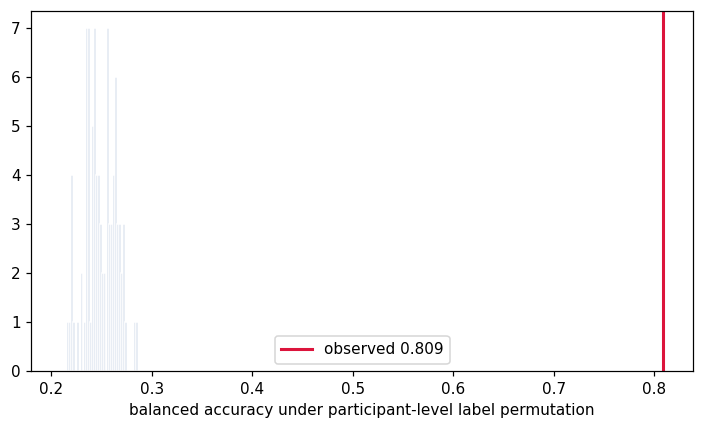

In [22]:
part_label = (pd.DataFrame({"pid": groups.values, "lab": y.values})
                .drop_duplicates().set_index("pid")["lab"])
pids = part_label.index.to_numpy()

def cv_score(y_vec):
    sc = []
    for tr, te in StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True,
                                       random_state=RANDOM_STATE).split(X, y_vec, groups):
        m = clone(best_pipe).fit(X.iloc[tr], y_vec.iloc[tr])
        sc.append(balanced_accuracy_score(y_vec.iloc[te], m.predict(X.iloc[te])))
    return np.mean(sc)

obs = results[BEST].mean()
null = np.empty(N_PERM)
for i in range(N_PERM):
    perm = pd.Series(rng.permutation(part_label.to_numpy()), index=pids)
    null[i] = cv_score(groups.map(perm).reset_index(drop=True))

p_acc = (np.sum(null >= obs) + 1) / (N_PERM + 1)
print(f"observed {obs:.3f}   null mean {null.mean():.3f}   p = {p_acc:.4f}  ({N_PERM} perms)")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(null, bins=40, color="#9db4d0", edgecolor="w")
ax.axvline(obs, color="crimson", lw=2, label=f"observed {obs:.3f}")
ax.set_xlabel("balanced accuracy under participant-level label permutation"); ax.legend()
fig.tight_layout(); fig.savefig(f"{OUTDIR}/03_permutation_accuracy.png", dpi=150); plt.show()

## Stage 7 — Which discriminants are interpretable?

Two tests for the same question.

**Bartlett / Wilks' lambda** is the classical sequential test: LD1..LDs jointly, then
LD2..LDs, and so on. It is computed below — but its *N* is the **row** count, so with rows
nested in participants every p-value is anticonservative and near-zero by construction.
**Descriptive only.**

**Permutation on each eigenvalue** is the defensible version: build a null for λ₁, λ₂, λ₃
under participant-level shuffling. Note this is only valid because the reduction step is
unsupervised — it never saw the labels, so permuting them afterwards is a legitimate null.

An LD explaining under ~5% of trace should not be interpreted regardless of its p-value.

In [23]:
pre  = Pipeline(best_pipe.steps[:-1]).fit(X)
Zred = pre.transform(X)
if "sel" in pre.named_steps:
    red_names = list(np.array(feat_names)[pre.named_steps["sel"].support_])
elif "pca" in pre.named_steps:
    red_names = [f"PC{i+1}" for i in range(Zred.shape[1])]
else:
    red_names = list(feat_names)
print(f"interpreting in a space of {Zred.shape[1]} variables")

def lda_eigs(Zm, yv):
    '''Generalised eigenvalues of B w.r.t. W - the quantity LDA maximises.'''
    cls = np.unique(yv); pp = Zm.shape[1]; grand = Zm.mean(0)
    W = np.zeros((pp, pp)); B = np.zeros((pp, pp))
    for c in cls:
        Zc = Zm[yv == c]; mc = Zc.mean(0); d = Zc - mc
        W += d.T @ d
        dm = (mc - grand)[:, None]; B += len(Zc) * dm @ dm.T
    W += np.eye(pp) * 1e-8
    ev = linalg.eigh(B, W, eigvals_only=True)
    return np.sort(np.real(ev))[::-1][:min(pp, len(cls) - 1)]

yv    = y.to_numpy()
lam   = lda_eigs(Zred, yv)
canon = np.sqrt(lam / (1 + lam))
prop  = lam / lam.sum()

pr = Zred.shape[1]
print("\nBartlett sequential test (PARAMETRIC - descriptive only):")
for k in range(len(lam)):
    wilks = np.prod(1 / (1 + lam[k:]))
    chi2  = -(N - 1 - (pr + g) / 2) * np.log(wilks)
    df    = (pr - k) * (g - 1 - k)
    print(f"  LD{k+1}..LD{len(lam)}: Wilks={wilks:.4f}  chi2={chi2:.1f}  df={df}  p={stats.chi2.sf(chi2, df):.3g}")

interpreting in a space of 39 variables

Bartlett sequential test (PARAMETRIC - descriptive only):
  LD1..LD3: Wilks=0.0407  chi2=2899.5  df=117  p=0
  LD2..LD3: Wilks=0.4145  chi2=797.5  df=76  p=9.15e-121
  LD3..LD3: Wilks=0.8808  chi2=114.9  df=37  p=6.43e-10


Participant-level permutation test on each discriminant:
  LD1: eigenvalue=9.190  canonical r=0.950   87.9% of trace  p=0.0099   INTERPRETABLE
  LD2: eigenvalue=1.125  canonical r=0.728   10.8% of trace  p=0.0099   INTERPRETABLE
  LD3: eigenvalue=0.135  canonical r=0.345    1.3% of trace  p=0.0099   INTERPRETABLE


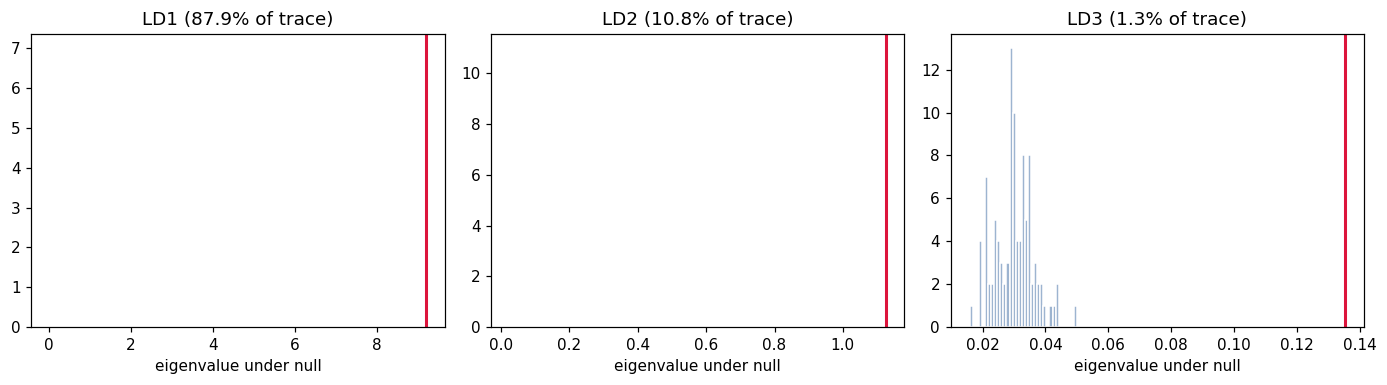

In [24]:
null_lam = np.empty((N_PERM, len(lam)))
for i in range(N_PERM):
    perm = pd.Series(rng.permutation(part_label.to_numpy()), index=pids)
    null_lam[i] = lda_eigs(Zred, groups.map(perm).to_numpy())

print("Participant-level permutation test on each discriminant:")
for k in range(len(lam)):
    pk = (np.sum(null_lam[:, k] >= lam[k]) + 1) / (N_PERM + 1)
    print(f"  LD{k+1}: eigenvalue={lam[k]:.3f}  canonical r={canon[k]:.3f}  "
          f"{prop[k]*100:5.1f}% of trace  p={pk:.4f}   "
          f"{'INTERPRETABLE' if pk < .05 else 'do NOT interpret'}")

fig, axes = plt.subplots(1, len(lam), figsize=(4.2*len(lam), 3.6), squeeze=False)
for k in range(len(lam)):
    a = axes[0, k]
    a.hist(null_lam[:, k], bins=35, color="#9db4d0", edgecolor="w")
    a.axvline(lam[k], color="crimson", lw=2)
    a.set_title(f"LD{k+1} ({prop[k]*100:.1f}% of trace)"); a.set_xlabel("eigenvalue under null")
fig.tight_layout(); fig.savefig(f"{OUTDIR}/04_permutation_eigenvalues.png", dpi=150); plt.show()

## Stage 8 — Are the loadings stable?

**Structure coefficients**, not weights. A structure coefficient is the correlation between
a feature and the discriminant scores, so it is immune to the cancellation that makes
weights unreadable under collinearity.

Two subtleties handled below:

- Resampling is over **participants**, not rows — otherwise the CIs are far too narrow.
- Discriminant axes have **arbitrary sign** across refits, so each bootstrap replicate is
  sign-aligned to the reference before pooling. Skipping this makes every CI straddle zero.

A feature is interpretable if its 95% CI excludes zero **and** its sign is consistent in
>95% of replicates. Everything else stays out of the text.

In [25]:
def structure_coefs(Zm, scores):
    out = np.empty((Zm.shape[1], scores.shape[1]))
    for j in range(Zm.shape[1]):
        for k in range(scores.shape[1]):
            out[j, k] = np.corrcoef(Zm[:, j], scores[:, k])[0, 1]
    return np.nan_to_num(out)

ref_lda    = LDA(solver="svd", n_components=len(lam)).fit(Zred, yv)
ref_scores = ref_lda.transform(Zred)
ref_struct = structure_coefs(Zred, ref_scores)

boot = np.full((N_BOOT, Zred.shape[1], len(lam)), np.nan)
for b in range(N_BOOT):
    take = rng.choice(pids, size=len(pids), replace=True)
    idx  = np.concatenate([np.where(groups.values == q)[0] for q in take])
    try:
        m = LDA(solver="svd", n_components=len(lam)).fit(Zred[idx], yv[idx])
        s = structure_coefs(Zred[idx], m.transform(Zred[idx]))
    except Exception:
        continue
    for k in range(len(lam)):
        if np.dot(s[:, k], ref_struct[:, k]) < 0:
            s[:, k] *= -1
    boot[b] = s
print("bootstrap done")

bootstrap done



--- LD1: 28/39 stable


,struct,lo,hi,sign_consistency,stable
RIGHT_mcp_tip_distance_mean,0.820,0.785,0.852,1.00,True
head_horizontal_sd,0.725,0.687,0.760,1.00,True
total_arm_acceleration_peak_n,0.679,0.642,0.720,1.00,True
RIGHT_fingertip_speed_mean,-0.545,-0.592,-0.469,1.00,True
RIGHT_thumb_index_distance_mean,-0.489,-0.540,-0.434,1.00,True
RIGHT_index_middle_distance_mean,-0.485,-0.521,-0.436,1.00,True
RIGHT_fingertip_speed_std,-0.433,-0.464,-0.395,1.00,True
head_speed_mean,0.418,0.357,0.476,1.00,True
lwrist_centre_peak_n,0.414,0.345,0.465,1.00,True
head_horizontal_mean,-0.404,-0.463,-0.345,1.00,True


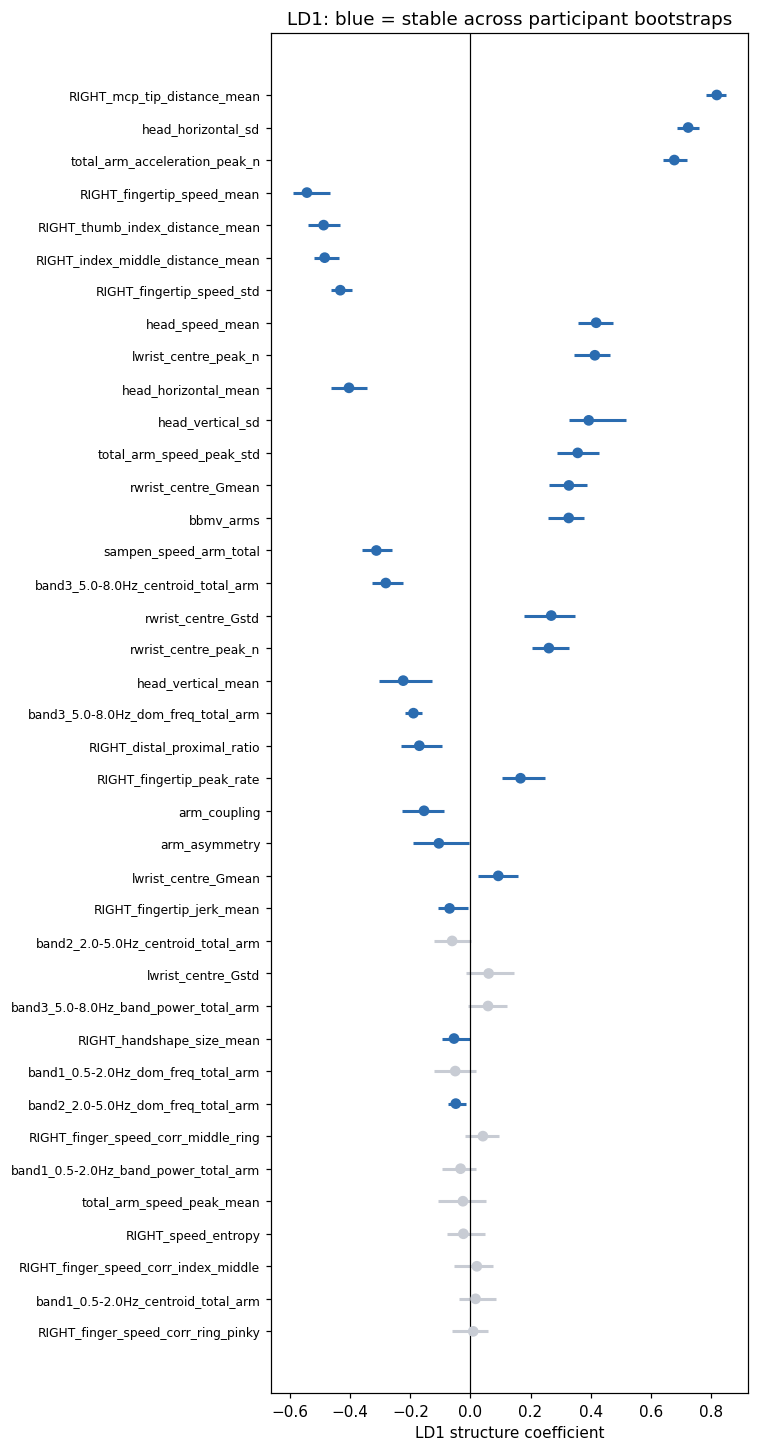


--- LD2: 26/39 stable


,struct,lo,hi,sign_consistency,stable
RIGHT_fingertip_peak_rate,-0.498,-0.541,-0.411,1.00,True
band3_5.0-8.0Hz_centroid_total_arm,-0.414,-0.494,-0.344,1.00,True
RIGHT_handshape_size_mean,-0.310,-0.412,-0.209,1.00,True
lwrist_centre_Gmean,0.304,0.201,0.390,1.00,True
RIGHT_fingertip_speed_mean,-0.297,-0.386,-0.218,1.00,True
total_arm_speed_peak_std,-0.279,-0.338,-0.206,1.00,True
band3_5.0-8.0Hz_dom_freq_total_arm,-0.272,-0.354,-0.176,1.00,True
head_vertical_mean,-0.262,-0.361,-0.157,1.00,True
RIGHT_distal_proximal_ratio,-0.248,-0.329,-0.141,1.00,True
RIGHT_fingertip_speed_std,-0.218,-0.308,-0.137,1.00,True


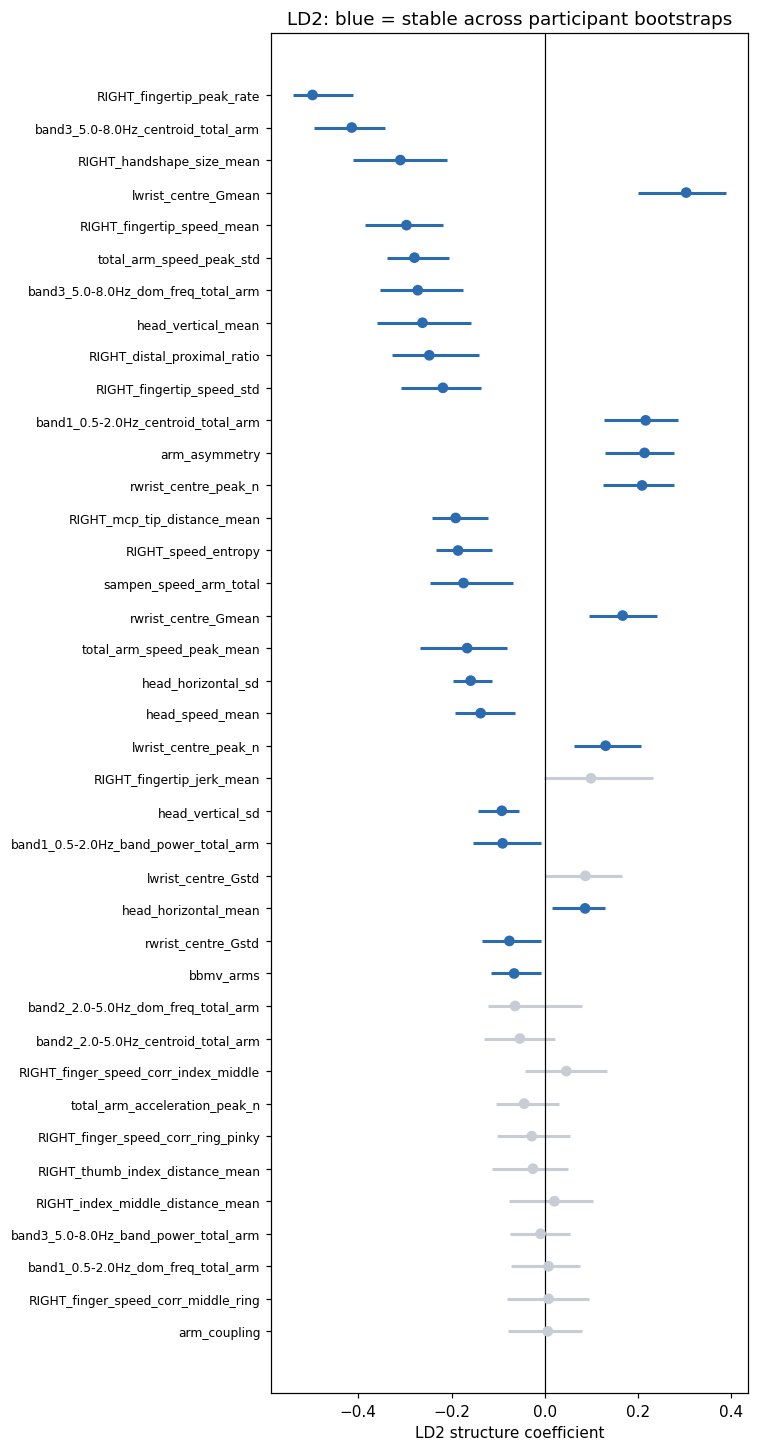

In [26]:
stability = {}
for k in range(min(2, len(lam))):
    lo = np.nanpercentile(boot[:, :, k], 2.5, axis=0)
    hi = np.nanpercentile(boot[:, :, k], 97.5, axis=0)
    sc = np.nanmean(np.sign(boot[:, :, k]) == np.sign(ref_struct[:, k]), axis=0)
    tab = pd.DataFrame({"struct": ref_struct[:, k], "lo": lo, "hi": hi,
                        "sign_consistency": sc}, index=red_names)
    tab["stable"] = (tab.lo * tab.hi > 0) & (tab.sign_consistency > .95)
    tab = tab.reindex(tab.struct.abs().sort_values(ascending=False).index)
    stability[k] = tab
    print(f"\n--- LD{k+1}: {int(tab.stable.sum())}/{len(tab)} stable")
    display(tab.round(3))

    o = tab.iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.30*len(o) + 1.6))
    col = np.where(o.stable, "#2b6cb0", "#c8ccd4")
    ax.errorbar(o.struct, range(len(o)), xerr=[o.struct - o.lo, o.hi - o.struct],
                fmt="none", ecolor=col, lw=2)
    ax.scatter(o.struct, range(len(o)), color=col, zorder=3)
    ax.axvline(0, color="k", lw=.8)
    ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index, fontsize=8)
    ax.set_xlabel(f"LD{k+1} structure coefficient")
    ax.set_title(f"LD{k+1}: blue = stable across participant bootstraps")
    fig.tight_layout(); fig.savefig(f"{OUTDIR}/05_loadings_LD{k+1}.png", dpi=150); plt.show()

## Stage 9 — Final figures

**Centroids first.** The sign of every loading is only readable relative to where the
groups sit on that axis. Print them before interpreting anything.

The confusion matrix is **out-of-fold**, so it reflects generalisation rather than fit. The
biplot is fit on all data — standard for a figure, but say so in the caption, because the
visual separation is optimistic relative to the cross-validated number.

In [27]:
cen = pd.DataFrame(ref_scores[:, :min(2, len(lam))],
                   columns=[f"LD{i+1}" for i in range(min(2, len(lam)))])
cen["grp"] = yv
print("group centroids - use these to read the SIGN of every loading:")
display(cen.groupby("grp").mean().round(2))

group centroids - use these to read the SIGN of every loading:


,LD1,LD2
grp,,
DGS,-3.14,-1.60
Gesture,4.95,-0.49
Learners_1,-0.91,0.90
Learners_2,-1.23,1.01


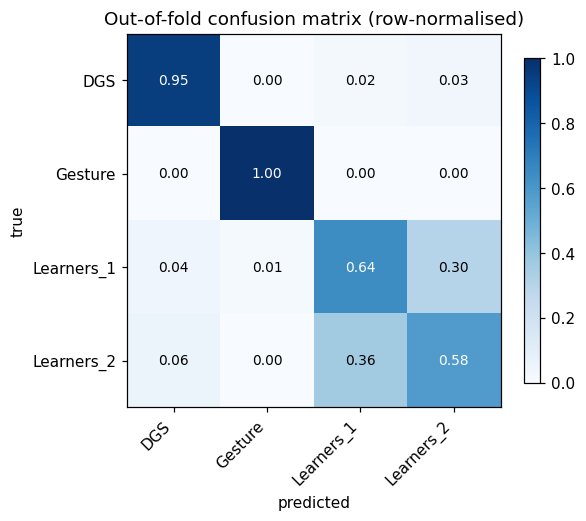

In [28]:
oof = cross_val_predict(clone(best_pipe), X, y, cv=splits, groups=groups)
cm  = confusion_matrix(y, oof, labels=classes, normalize="true")

fig, ax = plt.subplots(figsize=(5.6, 5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(g):
    for j in range(g):
        ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                color="white" if cm[i,j] > .5 else "black", fontsize=9)
ax.set_xticks(range(g)); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(g)); ax.set_yticklabels(classes)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Out-of-fold confusion matrix (row-normalised)")
fig.colorbar(im, shrink=.75); fig.tight_layout()
fig.savefig(f"{OUTDIR}/06_confusion.png", dpi=150); plt.show()

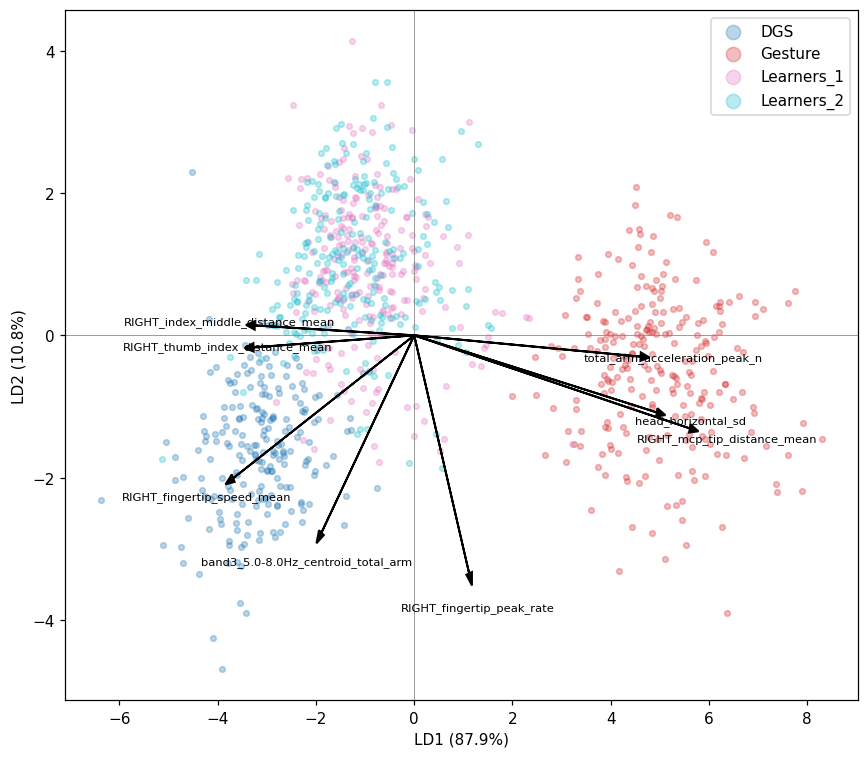

In [29]:
if len(lam) >= 2:
    fig, ax = plt.subplots(figsize=(8, 7))
    cols = plt.cm.tab10(np.linspace(0, 1, g))
    for c, cls_ in zip(cols, classes):
        m = yv == cls_
        ax.scatter(ref_scores[m, 0], ref_scores[m, 1], s=14, alpha=.30, color=c, label=cls_)
    mag   = np.hypot(ref_struct[:, 0], ref_struct[:, 1])
    sel   = np.argsort(mag)[::-1][:8]
    scale = .85 * np.abs(ref_scores[:, :2]).max()
    for j in sel:
        dx, dy = ref_struct[j, 0]*scale, ref_struct[j, 1]*scale
        ax.arrow(0, 0, dx, dy, color="k", lw=1.3, head_width=.12,
                 length_includes_head=True, zorder=5)
        ax.text(dx*1.1, dy*1.1, red_names[j], fontsize=7.5, ha="center")
    ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
    ax.set_xlabel(f"LD1 ({prop[0]*100:.1f}%)"); ax.set_ylabel(f"LD2 ({prop[1]*100:.1f}%)")
    ax.legend(markerscale=2.5); fig.tight_layout()
    fig.savefig(f"{OUTDIR}/07_biplot.png", dpi=150); plt.show()

## Optional — does PCA throw away your signal?

Only relevant if you go with `PCA+LDA`. PCA orders components by **total** variance, which
has nothing to do with group separation. This cell tests each component against group with
a univariate F-test and flags any **discarded** component that was informative.

If a discarded component has a large F, the variance cutoff is destroying your effect — use
`n_components` chosen by CV rather than by a variance threshold, or drop PCA entirely.

In [ ]:
pca_all = Pipeline([("sc", StandardScaler()),
                    ("pca", PCA(random_state=RANDOM_STATE))]).fit(X)
Zall = pca_all.transform(X)
F, pvals = f_classif(Zall, yv)
evr = pca_all.named_steps["pca"].explained_variance_ratio_
kept = int(np.searchsorted(np.cumsum(evr), 0.95) + 1)

chk = pd.DataFrame({"var_%": evr*100, "F_vs_group": F, "p": pvals},
                   index=[f"PC{i+1}" for i in range(len(F))])
chk["kept_at_95%"] = np.arange(len(F)) < kept
print(f"a 95% variance cutoff keeps {kept}/{len(F)} components")
display(chk.round(3).head(20))

lost = chk[(~chk["kept_at_95%"]) & (chk.p < .01)]
if len(lost):
    print("\n>> RED FLAG: these DISCARDED components carry group information:")
    display(lost.round(4))
else:
    print("\nOK: no discarded component carries appreciable group signal.")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(range(1, len(F)+1), F, color=np.where(chk["kept_at_95%"], "#2b6cb0", "#d65f5f"))
ax.set_xlabel("principal component (ordered by variance)")
ax.set_ylabel("F statistic vs group")
ax.set_title("blue = kept at 95% variance, red = discarded")
fig.tight_layout(); fig.savefig(f"{OUTDIR}/08_pca_signal_check.png", dpi=150); plt.show()

## Reporting checklist

- [ ] CV is **grouped on participant**; report the grouped number, not the ungrouped one
- [ ] Report **balanced accuracy** with the chance level (1/g) alongside it
- [ ] Report the **participant-level permutation p** for the classification
- [ ] Report **how many discriminants survived** the eigenvalue permutation test, and
      interpret only those
- [ ] Report **structure coefficients**, not raw weights, and only those marked stable
- [ ] State that the biplot is fit on all data while the accuracy is out-of-fold
- [ ] State whether `_n` features are counts or rates
- [ ] If QDA beat LDA, say so

### Red flags
| symptom | meaning |
|---|---|
| accuracy near 1.0 | leakage — ID column in `X`, or ungrouped CV |
| large opposing weights on correlated features | collinearity; use structure coefficients |
| Box's M p < .001 with large N | expected; not by itself a reason to abandon LDA |
| LD explaining < 5% of trace | do not interpret regardless of p-value |
| loading flips sign across bootstraps | not a finding |
| one group forms a very tight cluster | one participant dominating; colour the scatter by participant |